# Hawkes process: inferring a latent baseline intensity via GP flow matching

A Hawkes process is a self-exciting point process: each event temporarily raises the rate of future events. We give the baseline a GP prior on its log, $f \sim \mathcal{GP}(\mu, k)$, and treat the excitation parameters $\alpha, \beta > 0$ as known:

$$
\lambda(t \mid \mathcal{H}_t) = \underbrace{e^{f(t)}}_{\text{baseline}} + \underbrace{\sum_{t_i < t} \alpha\, e^{-\beta(t - t_i)}}_{\text{self-excitation}}, \qquad
\log p(\{t_i\} \mid f) = \sum_{i} \log \lambda(t_i \mid \mathcal{H}_{t_i}) - \int_0^T \lambda(t \mid \mathcal{H}_t)\, \mathrm{d}t.
$$

As in the inhomogeneous Poisson (LGCP) notebook, we sample from the GP prior with a flow and guide the samples towards $p(f \mid \{t_i\})$; the difficulty here is separating the smooth baseline from bursts caused by self-excitation.

## 1. Setup

In [1]:
import gpytorch
import matplotlib.pyplot as plt
import numpy as np
import torch

from flow_inference.conditions import BaseCondition
from flow_inference.flow_utils import build_grid_in_box
from flow_inference.flows import GaussianProcessFlow
from flow_inference.guidance import GuidanceMC
from flow_inference.sampler import IntegratorSampler

torch.set_default_dtype(torch.float64)

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"

SEED = 1066 if device == "cuda" else 12  # chosen for a clear visual example
T = 10.0            # observation window [0, T]
N = 256             # inference grid points
N_TRUTH = 2000      # fine grid for simulating the ground truth
NUM_SAMPLES = 100
NUM_STEPS = 500

TRUE_LENGTHSCALE = 1.0
TRUE_OUTPUTSCALE = 2.0
TRUE_MEAN = 0.5     # baseline rate exp(0.5) ≈ 1.6 events per unit time

ALPHA = 1.5         # excitation amplitude (known)
BETA = 10.0         # excitation decay rate (known)

## 2. Simulated data

Draw $f^*$ from the GP on a fine grid and simulate events with Ogata's thinning algorithm. Between events the self-excitation only decays, so its current value plus the maximum of the remaining baseline is a valid upper bound on the intensity.

In [3]:
torch.manual_seed(SEED)
t_truth = torch.linspace(0.0, T, N_TRUTH, device=device)

kernel_true = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel()).to(device)
kernel_true.base_kernel.lengthscale = TRUE_LENGTHSCALE
kernel_true.outputscale = TRUE_OUTPUTSCALE

with torch.no_grad():
    K_truth = kernel_true(t_truth.unsqueeze(-1)).evaluate()
    L_truth = torch.linalg.cholesky(K_truth + 1e-6 * torch.eye(N_TRUTH, device=device))
    f_truth = TRUE_MEAN + L_truth @ torch.randn(N_TRUTH, device=device)

t_truth_np = t_truth.cpu().numpy()
f_truth_np = f_truth.cpu().numpy()
baseline_truth = torch.exp(f_truth).cpu().numpy()


def simulate_hawkes(baseline, T, alpha, beta, rng):
    # Ogata thinning with the baseline given on a uniform grid over [0, T]
    N_grid = len(baseline)
    dt_grid = T / N_grid
    events = []
    t = 0.0

    while t < T:
        self_excit = sum(alpha * np.exp(-beta * (t - ti)) for ti in events)
        idx_curr = min(int(t / dt_grid), N_grid - 1)
        lambda_star = self_excit + baseline[idx_curr:].max()

        t_cand = t + rng.exponential(1.0 / lambda_star)
        if t_cand >= T:
            break

        # True intensity at the candidate, baseline linearly interpolated
        idx_lo = min(int(t_cand / dt_grid), N_grid - 2)
        frac = (t_cand / dt_grid) - idx_lo
        base_c = (1 - frac) * baseline[idx_lo] + frac * baseline[idx_lo + 1]
        excit_c = sum(alpha * np.exp(-beta * (t_cand - ti)) for ti in events)

        if rng.uniform() < (base_c + excit_c) / lambda_star:
            events.append(t_cand)
        t = t_cand

    return np.array(sorted(events))


rng = np.random.default_rng(SEED)
ev_np = simulate_hawkes(baseline_truth, T, ALPHA, BETA, rng)
t_events = torch.tensor(ev_np, device=device)
print(f"Observed events: {len(ev_np)}")

Observed events: 53


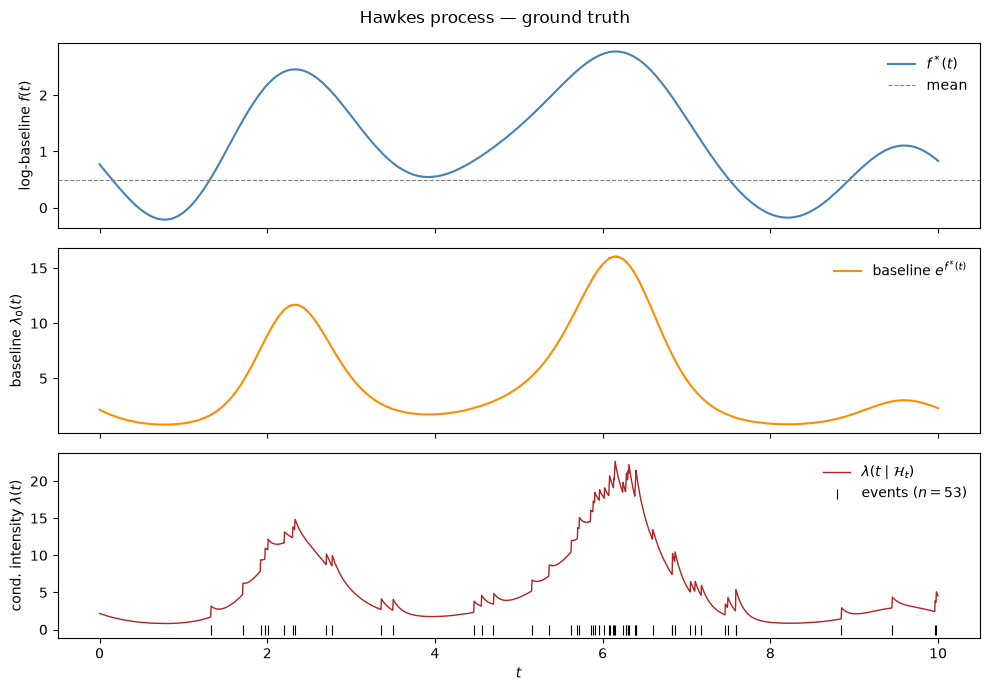

In [4]:
# True conditional intensity on the fine grid
lambda_cond_np = baseline_truth.copy()
for ti in ev_np:
    mask = t_truth_np > ti
    lambda_cond_np[mask] += ALPHA * np.exp(-BETA * (t_truth_np[mask] - ti))

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

axes[0].plot(t_truth_np, f_truth_np, color="steelblue", lw=1.5, label="$f^*(t)$")
axes[0].axhline(TRUE_MEAN, color="gray", lw=0.8, ls="--", label="mean")
axes[0].set_ylabel("log-baseline $f(t)$")
axes[0].legend(frameon=False)

axes[1].plot(t_truth_np, baseline_truth, color="darkorange", lw=1.5, label="baseline $e^{f^*(t)}$")
axes[1].set_ylabel("baseline $\\lambda_0(t)$")
axes[1].legend(frameon=False)

axes[2].plot(t_truth_np, lambda_cond_np, color="firebrick", lw=1.0, label="$\\lambda(t \\mid \\mathcal{H}_t)$")
axes[2].scatter(ev_np, np.zeros(len(ev_np)), marker="|", color="black",
                s=60, linewidths=0.8, label=f"events ($n={len(ev_np)}$)")
axes[2].set_xlabel("$t$")
axes[2].set_ylabel("cond. intensity $\\lambda(t)$")
axes[2].legend(frameon=False)

fig.suptitle("Hawkes process — ground truth", fontsize=12)
plt.tight_layout()
plt.show()

## 3. GP prior and sampler

The prior flow lives on an $N$-point grid. `build_grid_in_box` returns coordinates in $[0, 1)$, so the lengthscale is divided by $T$.

In [5]:
coords = build_grid_in_box(N, 1, device)  # (N, 1)

kernel_prior = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel()).to(device)
kernel_prior.base_kernel.lengthscale = TRUE_LENGTHSCALE / T
kernel_prior.outputscale = TRUE_OUTPUTSCALE

prior_mean = gpytorch.means.ConstantMean().to(device)
with torch.no_grad():
    prior_mean.constant.fill_(TRUE_MEAN)

flow = GaussianProcessFlow(kernel_prior, prior_mean, coords, device=device)
sampler = IntegratorSampler(flow=flow)

t_infer = coords.squeeze(-1).cpu().numpy() * T  # grid in original time units

In [6]:
def plot_posterior(samples, title=""):
    # Posterior mean and 90% interval of f and exp(f) against the truth
    samples_f = samples.squeeze(1).cpu().numpy()  # (B, N)
    post_mean = samples_f.mean(axis=0)
    post_lo = np.quantile(samples_f, 0.05, axis=0)
    post_hi = np.quantile(samples_f, 0.95, axis=0)

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

    axes[0].plot(t_truth_np, f_truth_np, "k-", lw=2, label="$f^*$ (truth)", zorder=4)
    axes[0].fill_between(t_infer, post_lo, post_hi, color="steelblue", alpha=0.3, label="90% CI")
    axes[0].plot(t_infer, post_mean, color="steelblue", lw=1.5, label="posterior mean")
    axes[0].set_ylabel("log-baseline $f(t)$")
    axes[0].legend(frameon=False)

    axes[1].plot(t_truth_np, baseline_truth, "k-", lw=2, label="$e^{f^*}$ (truth)", zorder=4)
    axes[1].fill_between(t_infer, np.exp(post_lo), np.exp(post_hi),
                         color="darkorange", alpha=0.3, label="90% CI")
    axes[1].plot(t_infer, np.exp(post_mean), color="darkorange", lw=1.5, label="posterior mean")
    axes[1].scatter(ev_np, np.zeros(len(ev_np)), marker="|", color="black",
                    s=60, linewidths=0.8, label=f"events ($n={len(ev_np)}$)")
    axes[1].set_xlabel("$t$")
    axes[1].set_ylabel("baseline $e^{f(t)}$")
    axes[1].legend(frameon=False)

    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()

## 4. Hawkes likelihood

Only the baseline depends on $f$, so everything else is precomputed: the excitation at each event, $H_i = \sum_{j: t_j < t_i} \alpha e^{-\beta(t_i - t_j)}$, and the closed-form integral of the excitation, $C = \frac{\alpha}{\beta} \sum_i \bigl(1 - e^{-\beta(T - t_i)}\bigr)$. With $f(t_i)$ linearly interpolated from the grid, `logp` evaluates

$$\sum_i \log\bigl(e^{f(t_i)} + H_i\bigr) - \Delta t\sum_j e^{f_j} - C.$$

In [7]:
class HawkesCondition(BaseCondition):
    def __init__(self, event_times: torch.Tensor, T: float, N: int, alpha: float, beta: float):
        super().__init__()
        self.register_buffer("dt", torch.tensor(T / N))

        # Excitation at each event from strictly earlier events, H_i
        diff = event_times.unsqueeze(1) - event_times.unsqueeze(0)  # (n, n)
        H = (alpha * torch.exp(-beta * diff) * (diff > 0)).sum(dim=1)  # (n,)
        self.register_buffer("H", H)

        # Integral of the excitation over [0, T], C
        integral_self = (alpha / beta * (1 - torch.exp(-beta * (T - event_times)))).sum()
        self.register_buffer("integral_self", integral_self)

        # Linear interpolation weights of each event onto the grid
        frac_idx = (event_times / T * N).clamp(0.0, N - 1.0 - 1e-9)
        idx_lo = frac_idx.long()
        frac = frac_idx - idx_lo.double()
        self.register_buffer("idx_lo", idx_lo)
        self.register_buffer("w_lo", 1.0 - frac)
        self.register_buffer("w_hi", frac)

    def logp(self, x: torch.Tensor) -> torch.Tensor:
        f = x.squeeze(1)  # (B, N)
        f_at_events = self.w_lo * f[:, self.idx_lo] + self.w_hi * f[:, self.idx_lo + 1]  # (B, n)
        event_term = torch.log(torch.exp(f_at_events) + self.H).sum(dim=-1)
        integral_baseline = self.dt * torch.exp(f).sum(dim=-1)
        return event_term - integral_baseline - self.integral_self

## 5. Guided sampling

  0%|          | 0/499 [00:00<?, ?it/s]

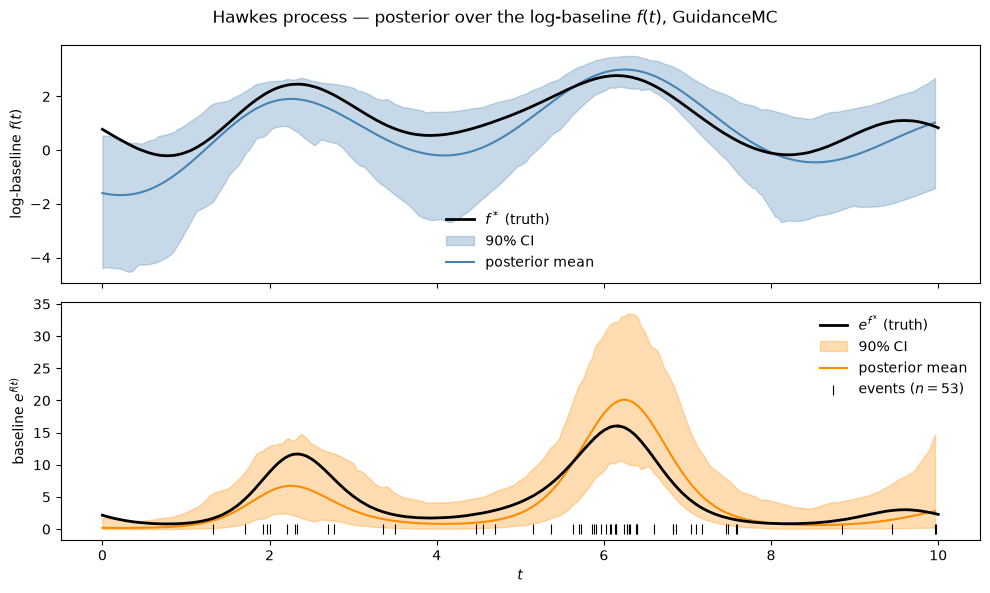

In [8]:
condition = HawkesCondition(t_events, T, N, ALPHA, BETA).to(device)
guidance = GuidanceMC(flow, condition, num_mc_samples=1).to(device)

torch.manual_seed(SEED)
samples = sampler.sample(NUM_SAMPLES, guidance=guidance, num_steps=NUM_STEPS, time_schedule="snr")
plot_posterior(samples, title="Hawkes process — posterior over the log-baseline $f(t)$, GuidanceMC")